## Stepwise Spectral Pipeline Demo (Single Raw Reading)
This section shows one `.npy` reading through: raw spectrum -> mouse optic filtering -> AUC with S/M/rod kernels -> M/S ratio.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from spec_data_utils import (
    add_interpolated_and_filtered_spectrum,
    load_pr_kernels_300_599,
    UNIVERSAL_WAVELENGTHS,
)

In [2]:
raw_npy = os.path.expanduser('~/Github/SCAM/one_scam_data/ONE_SCAM_20260308_141257/scan_data/scan_iter0_0_pan0_tilt18.npy')
scan = np.load(raw_npy, allow_pickle=True).item()

wavelength = np.asarray(scan['wavelengths'], dtype=np.float64)
spectrum = np.asarray(scan['intensity'], dtype=np.float64)

df_one = pd.DataFrame([{
    'wavelength': wavelength,
    'spectrum': spectrum,
    'adjusted_corrected_spectrum': spectrum,
}])

In [3]:
df_one = add_interpolated_and_filtered_spectrum(df_one, spectrum_col='adjusted_corrected_spectrum')

interp = df_one.loc[0, 'interpolated_spectrum']
filt = df_one.loc[0, 'filtered_spectrum']

kernels = load_pr_kernels_300_599()
x = kernels['wavelength']
s_curve = filt * kernels['scone']
m_curve = filt * kernels['mcone']
r_curve = filt * kernels['rod']

auc_s = np.trapezoid(s_curve, x=x)
auc_m = np.trapezoid(m_curve, x=x)
auc_r = np.trapezoid(r_curve, x=x)
ratio_m_over_s = auc_m / auc_s if auc_s != 0 else np.nan

print('Raw file:', raw_npy)
print('AUC_S:', auc_s)
print('AUC_M:', auc_m)
print('AUC_rod:', auc_r)
print('AUC_M / AUC_S:', ratio_m_over_s)

Raw file: /Users/dengyuyao/Github/SCAM/one_scam_data/ONE_SCAM_20260308_141257/scan_data/scan_iter0_0_pan0_tilt18.npy
AUC_S: 55431.89431658988
AUC_M: 452919.46738078375
AUC_rod: 438044.5490864472
AUC_M / AUC_S: 8.170737676652559


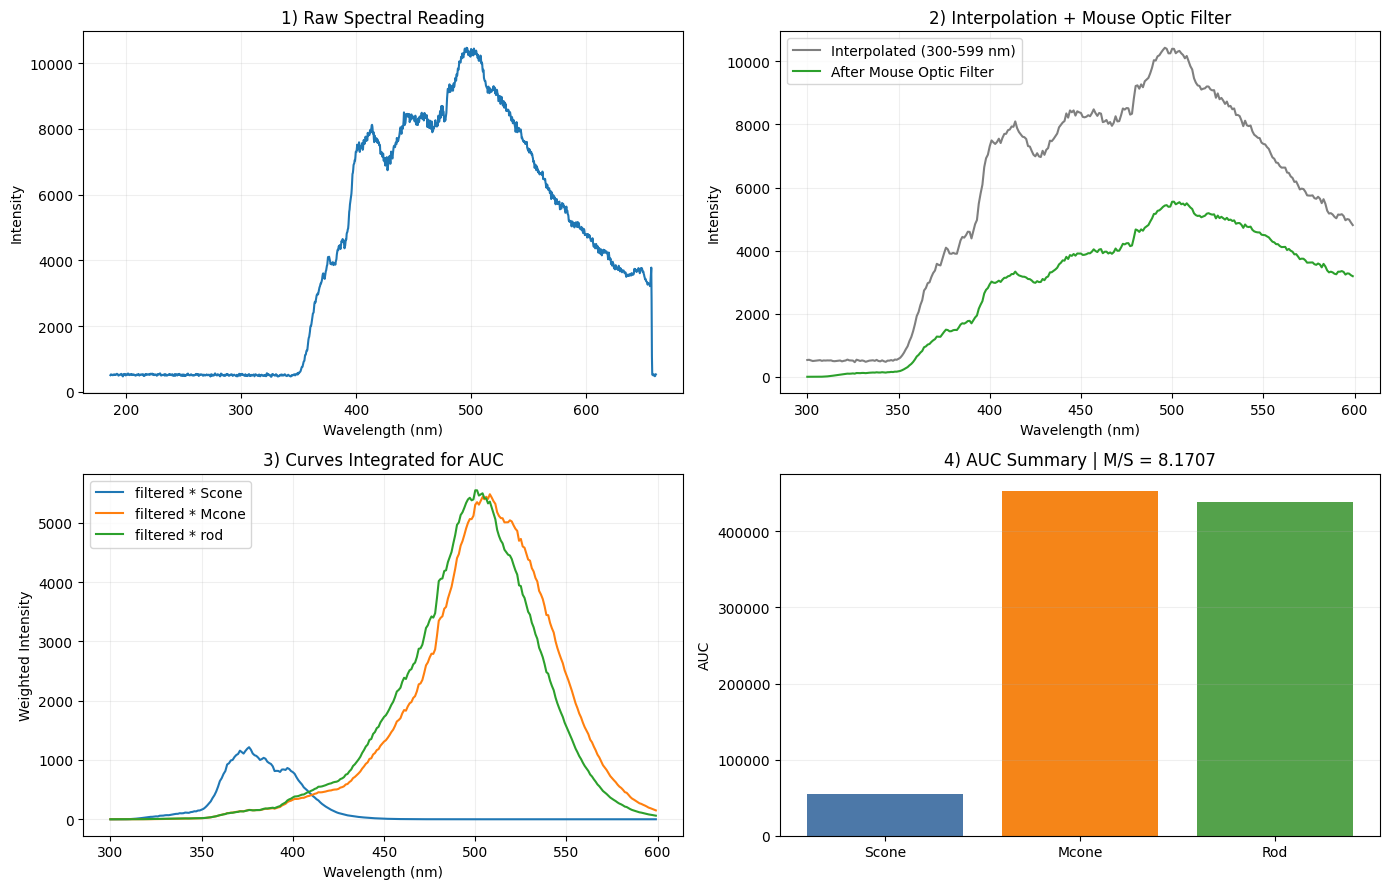

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Raw spectrum
axes[0, 0].plot(wavelength, spectrum, color='tab:blue', lw=1.5)
axes[0, 0].set_title('1) Raw Spectral Reading')
axes[0, 0].set_xlabel('Wavelength (nm)')
axes[0, 0].set_ylabel('Intensity')
axes[0, 0].grid(alpha=0.2)

# 2) Interpolated + optic-filtered
axes[0, 1].plot(UNIVERSAL_WAVELENGTHS, interp, label='Interpolated (300-599 nm)', color='tab:gray')
axes[0, 1].plot(UNIVERSAL_WAVELENGTHS, filt, label='After Mouse Optic Filter', color='tab:green')
axes[0, 1].set_title('2) Interpolation + Mouse Optic Filter')
axes[0, 1].set_xlabel('Wavelength (nm)')
axes[0, 1].set_ylabel('Intensity')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.2)

# 3) Weighted curves for AUC
axes[1, 0].plot(x, s_curve, label='filtered * Scone', lw=1.5)
axes[1, 0].plot(x, m_curve, label='filtered * Mcone', lw=1.5)
axes[1, 0].plot(x, r_curve, label='filtered * rod', lw=1.5)
axes[1, 0].set_title('3) Curves Integrated for AUC')
axes[1, 0].set_xlabel('Wavelength (nm)')
axes[1, 0].set_ylabel('Weighted Intensity')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.2)

# 4) AUC summary + ratio
labels = ['Scone', 'Mcone', 'Rod']
vals = [auc_s, auc_m, auc_r]
axes[1, 1].bar(labels, vals, color=['#4C78A8', '#F58518', '#54A24B'])
axes[1, 1].set_title(f'4) AUC Summary | M/S = {ratio_m_over_s:.4f}')
axes[1, 1].set_ylabel('AUC')
axes[1, 1].grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# Explicit view: before/after mouse optic filter + transmittance
import os
import numpy as np
import matplotlib.pyplot as plt

eye_csv = os.path.expanduser('~/Github/SCAM/config/Mouse_transmittance.csv')
eye = np.loadtxt(eye_csv, delimiter=',')
eye_w = eye[:, 0]
eye_t = eye[:, 1]
mask = (eye_w >= 300) & (eye_w <= 599)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(UNIVERSAL_WAVELENGTHS, interp, label='Interpolated (before optic filter)', color='tab:gray', lw=1.5)
ax1.plot(UNIVERSAL_WAVELENGTHS, filt, label='Filtered (after optic filter)', color='tab:green', lw=2.0)
ax1.set_xlabel('Wavelength (nm)')
ax1.set_ylabel('Intensity')
ax1.grid(alpha=0.2)

ax2 = ax1.twinx()
ax2.plot(eye_w[mask], eye_t[mask], label='Mouse transmittance (%)', color='tab:red', alpha=0.8)
ax2.set_ylabel('Transmittance (%)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc='upper right')
plt.title('Mouse Optic Filtering: Before vs After')
plt.tight_layout()
plt.show()

In [ ]:
# Overlay filtered spectrum with S/M/Rod opsin sensitivity curves
import matplotlib.pyplot as plt

kernels = load_pr_kernels_300_599()
x = kernels['wavelength']

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(x, filt, color='tab:green', lw=2.0, label='Filtered spectrum')
ax1.set_xlabel('Wavelength (nm)')
ax1.set_ylabel('Filtered intensity', color='tab:green')
ax1.tick_params(axis='y', labelcolor='tab:green')
ax1.grid(alpha=0.2)

ax2 = ax1.twinx()
ax2.plot(x, kernels['scone'], color='#4C78A8', lw=1.5, label='S-cone sensitivity')
ax2.plot(x, kernels['mcone'], color='#F58518', lw=1.5, label='M-cone sensitivity')
ax2.plot(x, kernels['rod'], color='#54A24B', lw=1.5, label='Rod sensitivity')
ax2.set_ylabel('Relative sensitivity', color='black')

l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lb1 + lb2, loc='upper right')
plt.title('Filtered Spectrum vs Opsin Sensitivity Curves')
plt.tight_layout()
plt.show()